# Multimodal AI Media Assistant — demonstration

This notebook demonstrates the system; the implementation lives in the
`media_assistant/` package. Nothing substantial is defined here, so the
same code runs from the notebook, the CLI, and the tests.

| Part | Where it lives | Shown below |
|---|---|---|
| 1 · media ingestion + ASR | `media.py`, `speech.py` | §1 |
| 2 · LLM analysis + structured output | `language.py` | §2 |
| 3 · semantic search + RAG | `chunking.py`, `retrieval.py` | §3 |
| 4 · tool-using agent | `tools.py`, `agent.py` | §4 |
| 5 · multilingual extension (Option C) | `multilingual.py` | §5 |
| 6 · reliability and tests | `reliability.py`, `tests/test_smoke.py` | §6 |
| 7 · artifacts | `report.py` | §7 |

Everything below can also be produced in one command:

```bash
python -m media_assistant.cli --media sample_media/meeting.wav
```

**Runtime warning.** On an Apple M1 the 4B language model generates about
5 tokens/second, so the full notebook takes roughly 25–35 minutes. Set
`USE_FIXTURE = True` in the setup cell to skip transcription while
developing.

In [1]:
%load_ext autoreload
%autoreload 2

import json
from pathlib import Path

from media_assistant import Config
from media_assistant.assistant import MediaAssistant
from media_assistant.utils import configure_logging, format_segment_line

configure_logging()

# --- what to run on -------------------------------------------------------
# Point MEDIA_PATH at your recording. USE_FIXTURE loads a hand-written
# transcript instead, which skips the 2-minute transcription step while
# developing the later stages. The submitted results were produced with
# USE_FIXTURE = False.
MEDIA_PATH = Path("sample_media/meeting.wav")
USE_FIXTURE = not MEDIA_PATH.exists()
FIXTURE_PATH = Path("tests/fixtures/sample_transcript.json")

config = Config()
print(json.dumps(config.describe(), indent=2))

{
  "asr_model": "openai/whisper-large-v3-turbo",
  "translate_model": "openai/whisper-large-v3",
  "llm_model": "Qwen/Qwen3-4B-Instruct-2507",
  "embedding_model": "Qwen/Qwen3-Embedding-0.6B",
  "device": "mps",
  "asr_dtype": "float16",
  "llm_dtype": "bfloat16",
  "embedding_dtype": "float32",
  "target_sample_rate": 16000,
  "asr_use_chunked": false,
  "asr_chunk_length_s": 30,
  "asr_batch_size": 1,
  "chunk_target_seconds": 30.0,
  "chunk_max_seconds": 45.0,
  "chunk_overlap_segments": 1,
  "top_k": 3,
  "min_similarity": 0.42,
  "llm_max_new_tokens": 1024,
  "llm_temperature": 0.0,
  "analysis_max_retries": 2,
  "max_agent_steps": 5,
  "analysis_language": "English",
  "seed": 20260811
}


## 1 · Media ingestion and timestamped transcription

`probe_metadata` inspects the container before anything is decoded, so a
file with no audio track is caught up front rather than halfway through
transcription. There is no system `ffmpeg` on this machine — every call
goes through the binary bundled with `imageio-ffmpeg`.

In [2]:
from media_assistant.media import probe_metadata
from media_assistant.exceptions import MediaError

if MEDIA_PATH.exists():
    print(json.dumps(probe_metadata(MEDIA_PATH), ensure_ascii=False, indent=2))
else:
    print(f"{MEDIA_PATH} does not exist yet — running from the fixture transcript.")

# Error handling, shown rather than asserted (see §6 for the full check set).
for bad_input in ["sample_media/does_not_exist.wav", "pyproject.toml"]:
    try:
        probe_metadata(bad_input)
    except (FileNotFoundError, MediaError) as exc:
        print(f"{bad_input!r} -> {type(exc).__name__}: {exc}")

{
  "path": "sample_media/meeting.wav",
  "filename": "meeting.wav",
  "container": "wav",
  "size_bytes": 8659662,
  "duration_seconds": 270.61,
  "has_audio": true,
  "has_video": false,
  "audio_codec": "pcm_s16le",
  "audio_sample_rate": 16000,
  "audio_layout": "mono"
}
'sample_media/does_not_exist.wav' -> FileNotFoundError: Media file not found: sample_media/does_not_exist.wav
'pyproject.toml' -> MediaError: Could not read a duration from pyproject.toml; it does not look like a media file ffmpeg can decode.


In [3]:
assistant = MediaAssistant(config)

if USE_FIXTURE:
    fixture = json.loads(FIXTURE_PATH.read_text(encoding="utf-8"))
    assistant.use_transcript(fixture["segments"], fixture["metadata"])
    print(f"Loaded {len(assistant.segments)} segments from the fixture.")
else:
    # Transcribes, runs the Whisper translate pass, builds the index, and
    # runs the structured analysis — in that order, so the ASR model is
    # released before the language model is loaded.
    summary = assistant.process(MEDIA_PATH)
    print(json.dumps(summary["transcript_metadata"], ensure_ascii=False, indent=2))

INFO | meeting.wav is already mono 16000 Hz WAV; using it directly


INFO | Transcribing meeting.wav


/Users/wudongrun/Downloads/Final_Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO | Loading ASR model openai/whisper-large-v3-turbo on mps (float16)


WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 5072.87it/s]

INFO | LLM ready in 14.9s


INFO | Analysis validated on attempt 1/3


{
  "asr_model": "openai/whisper-large-v3-turbo",
  "asr_task": "transcribe",
  "asr_forced_language": null,
  "asr_dtype": "float16",
  "device": "mps",
  "sample_rate": 16000,
  "audio_duration_seconds": 270.612,
  "transcription_seconds": 152.9,
  "realtime_factor": 0.565,
  "segment_count": 55,
  "long_form_algorithm": "sequential",
  "confidence_note": "No per-segment confidence score is exposed. Where the decoder reports avg_logprob it is passed through unchanged as a mean token log probability; it is not calibrated and is never rescaled into a percentage.",
  "source_media": {
    "path": "sample_media/meeting.wav",
    "filename": "meeting.wav",
    "container": "wav",
    "size_bytes": 8659662,
    "duration_seconds": 270.61,
    "has_audio": true,
    "has_video": false,
    "audio_codec": "pcm_s16le",
    "audio_sample_rate": 16000,
    "audio_layout": "mono"
  }
}


In [4]:
# Timestamps are numeric internally; they are formatted only for display.
for segment in assistant.segments[:12]:
    print(format_segment_line(segment), f"| {segment.get('language')}")
print(f"\n… {len(assistant.segments)} segments total")

[00:00.0 → 00:24.5] 大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记录,今天要勾四件事,第一是转录管线的进展,第二是结构和分析和检索,第三是工具Agent的设计,第四是多语言课程和提交时间。 | chinese
[00:38.5 → 00:47.5] Let's start with part one, the transcription pipeline, Chen Zhiyuan got Whisper Large B3 Turbo running on Collab last Thursday on our 5-minute 40-second test recording.It produced 47 timestamped segments, and the whole transcription took about 50 seconds on a T4. | english
[00:47.5 → 00:57.5] We check the segment boundaries by hand, and only 3 of them we split at an awkward place, which is good enough for the chunking we want to do later. | english
[00:57.5 → 01:04.5] 第二部分和第三部分是我做的,结构和分析这块,我让模型一样的复习成。 | chinese
[01:04.5 → 01:07.5] 8个必须自断,都要较硬。 | chinese
[01:07.5 → 01:16.5] 列表自断必须是真的列表,第一版大概有五分之一的概率会在JSON外面做出一段解释文字,我加了从事,最多从事两次。 | chinese
[01:16.5 → 01:18.5] 现在基本稳定了 | chinese
[01:18.5 → 01:21.5] 检索这边,我按30秒左右一块来接 | chinese
[01:21.5 → 01:24.5] 整段录音一共,切出19个chunk | chinese
[01:24.5 → 01:29.5] 我们用其签问embedding 0.6b 测了12个跨语言查询 |

## 2 · LLM analysis with validated structured output

The model is asked for JSON; the JSON is then checked in Python. If a
required key is missing, a field has the wrong type, or a list-valued
field is not a list, the specific problems go back to the model and it is
asked to fix them — up to `config.analysis_max_retries` times. A
malformed analysis is never returned.

In [5]:
if not assistant.analysis:
    assistant.analyse()

analysis = assistant.analysis
print(analysis["title"], "\n")
print(analysis["summary"], "\n")
for point in analysis["key_points"]:
    print(" •", point)
print("\nAction items:")
for item in analysis["action_items"]:
    print(f"  - {item['description']}  (owner: {item['owner']}, due: {item['due']})")
print("\nValidation:", json.dumps(analysis["_validation"], indent=2))

多摩台媒体助手寂寞项目第三次碰头会议 

会议讨论了转录管线、结构化分析与检索、工具Agent设计以及多语言课程的进展和计划。转录管线使用Whisper Large B3 Turbo在T4上运行，结果稳定，仅少量边界问题。结构化输出要求列表项必须真实，且解释文字最多出现两次，检索部分在跨语言查询中表现良好。Agent设计包含三个工具，运行步骤限制为5步，避免内存溢出。项目最终确定采用Ocean C多语言模式，不进行整列识别，原文与英文翻译需分开存储。提交截止日期为8月15日，演示视频定于8月13日完成，后续会议安排在8月8日。 

 • 转录管线使用Whisper Large B3 Turbo在T4上运行，50秒内完成5分钟40秒录音的转录，仅3个边界分割位置不理想。
 • 结构化输出要求列表项必须真实，解释性文字最多出现两次，当前版本已基本稳定。
 • 检索测试显示12个跨语言查询中有10个在前3个结果中命中正确频段，结果可接受。
 • Agent设计包含搜索转录、统计维度和获取媒体元数据三个工具，运行步数限制为5步，内存不足时需卸载模型并清空CUDA显存。
 • 项目最终确定采用Ocean C多语言模式，保留中文人文转录并生成英文翻译，两者分开存储。
 • 提交截止日期为8月15日，演示视频定于8月13日完成，会议决定在8月8日进行下一次碰头。

Action items:
  - Freyya在8月9日前完成一人多工具演示  (owner: Freyya, due: 2026-08-09)
  - 陈志远添加数字规范化处理，解决Whisper输出中文数字时阿拉伯数字或汉字混用的问题  (owner: Chen Zhiyuan, due: None)
  - DOM负责录制演示视频  (owner: DOM, due: None)
  - 记录人在此之前完成README初稿，明确实测的硬件和模型配置，不照搬推荐配置  (owner: Wu Dongren, due: None)

Validation: {
  "attempts": 1,
  "max_attempts": 3,
  "model": "Qwen/Qwen3-4B-Instruct-2507",
  "checked": [
    "action_items",
    "entities"

In [6]:
# What the validator rejects. These are the checks the brief requires:
# required keys, field types, and list-valued fields really being lists.
from media_assistant.language import check_analysis

broken = {
    "missing keys": {"title": "only a title"},
    "key_points is a string": {**{k: v for k, v in analysis.items() if k != "_validation"},
                               "key_points": "a, b, c"},
    "too few key points": {**{k: v for k, v in analysis.items() if k != "_validation"},
                           "key_points": ["one", "two"]},
}
for label, candidate in broken.items():
    print(f"{label:26s} -> {check_analysis(candidate)}")

missing keys               -> ['missing required keys: action_items, entities, follow_up_questions, key_points, languages, summary, topics']
key_points is a string     -> ["'key_points' must be list, got str"]
too few key points         -> ["'key_points' needs at least 3 items, got 2"]


## 3 · Semantic search and grounded question answering

Segments are grouped into chunks of about 30 seconds. Two rules matter:
a chunk never spans a change of language (mixing two languages into one
vector blurs the boundary that makes cross-lingual retrieval testable),
and neighbouring chunks overlap by one segment so a fact stated across a
boundary is still whole somewhere.

In [7]:
print(json.dumps(assistant.index.summary, ensure_ascii=False, indent=2))

for hit in assistant.search("what did they decide about the multimodal extension?"):
    print(f"{hit['chunk_id']}  {hit['timespan']}  {hit['score']:.4f}  {hit['language']:8s} "
          f"{hit['text'][:70]}")

{
  "chunk_count": 11,
  "mean_duration_seconds": 25.04,
  "min_duration_seconds": 14.0,
  "max_duration_seconds": 37.0,
  "chunks_per_language": {
    "chinese": 7,
    "english": 4
  },
  "covered_seconds": 269.14,
  "embedding_model": "Qwen/Qwen3-Embedding-0.6B",
  "embedding_dimension": 1024
}


C10  03:34.5–04:08.1  0.4084  chinese  这会影响CountMentions这个工具的统计陈志远说他加一层规议化最后规变今天的决定和行动想决定有三个第一,多模胎扩展确定的选Optio
C07  02:18.5–02:44.1  0.3640  chinese  第五部分我们选的是Ocean C,多语言模式,不做整列识别。我们的测试录音本身就是中音调替的,所以要保留人文转录,还单独生产一份英文翻译,两
C01  00:00.0–00:24.5  0.3611  chinese  大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记录,今天要勾四件事,第一是转


### The five required test questions

Two straightforward factual questions, one paraphrase whose wording does
not appear in the recording, one that needs more than one chunk, and one
the recording cannot answer. For each: the retrieved chunks with their
similarity scores, then the answer with its timestamp citations — so
retrieval and generation can be judged separately.

In [8]:
from media_assistant.demo import DEFAULT_RAG_QUESTIONS

rag_results = []
for number, question in enumerate(DEFAULT_RAG_QUESTIONS, start=1):
    result = assistant.ask(question.question)
    rag_results.append({"category": question.category,
                        "expectation": question.expectation,
                        "result": result})

    print(f"\n{'=' * 78}\nQ{number} [{question.category}]  {question.question}")
    print(f"   why: {question.expectation}")
    print("   retrieved:")
    for hit in result["retrieved"]:
        print(f"     {hit['rank']}. {hit['chunk_id']}  {hit['timespan']}  "
              f"score={hit['score']:.4f}  {hit['text'][:56]}")
    print(f"   answered: {result['answered']}"
          + (f"   reason: {result['refusal_reason']}" if result["refusal_reason"] else ""))
    print(f"   answer: {result['answer']}")
    if result.get("citations"):
        print("   citations:", ", ".join(
            c["text"] + ("" if c["matches_retrieved_chunks"] else " (NOT in evidence!)")
            for c in result["citations"]))


Q1 [factual]  How many timestamped segments did Whisper produce on the test recording?
   why: Stated directly in the English part of the recording.
   retrieved:
     1. C02  00:38.5–00:57.5  score=0.6609  Let's start with part one, the transcription pipeline, C
     2. C09  03:09.5–03:39.2  score=0.4922  還有兩個沒解決的問題第一,本地跑的時候沒有因為拿顯卡,只能換更小的模型ReadMe必须写清楚我们实测的硬件和模型
     3. C07  02:18.5–02:44.1  score=0.4521  第五部分我们选的是Ocean C,多语言模式,不做整列识别。我们的测试录音本身就是中音调替的,所以要保留人文转录
   answered: True
   answer: Whisper produced 47 timestamped segments on the test recording [C02 | 00:38.5–00:57.5].
   citations: [C02 | 00:38.5–00:57.5]



Q2 [factual]  整段录音一共切出了多少个 chunk？
   why: Stated directly in the Chinese part of the recording.
   retrieved:
     1. C04  01:21.5–01:35.5  score=0.6945  整段录音一共,切出19个chunk我们用其签问embedding 0.6b 测了12个跨语言查询有10个在头3里
     2. C03  00:57.5–01:24.5  score=0.6717  第二部分和第三部分是我做的,结构和分析这块,我让模型一样的复习成。8个必须自断,都要较硬。列表自断必须是真的列表
     3. C02  00:38.5–00:57.5  score=0.6272  Let's start with part one, the transcription pipeline, C
   answered: True
   answer: 整段录音一共切出了19个chunk [C04 | 01:21.5–01:35.5].
   citations: [C04 | 01:21.5–01:35.5]



Q3 [paraphrased]  agent 最多能跑几轮？
   why: The recording says 'the loop is capped at five steps' in English. The question shares no wording with it and is in the other language.
   retrieved:
     1. C05  01:35.5–02:12.5  score=0.4641  Now part for the agent, Ryanair is building a tool loop,
     2. C01  00:00.0–00:24.5  score=0.3782  大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记
     3. C10  03:34.5–04:08.1  score=0.3288  这会影响CountMentions这个工具的统计陈志远说他加一层规议化最后规变今天的决定和行动想决定有三个第一,
   answered: True
   answer: The agent loop is kept at 5 steps [C05 | 01:35.5–02:12.5].
   citations: [C05 | 01:35.5–02:12.5]



Q4 [multi-chunk]  agent 的多工具演示能在提交截止日期之前做完吗？
   why: Needs the 9 August action-item deadline (Chinese) and the 15 August submission deadline (English), which are in different chunks and different languages.
   retrieved:
     1. C08  02:44.9–03:09.5  score=0.5322  About the schedule The submission deadline is August 15t
     2. C05  01:35.5–02:12.5  score=0.4823  Now part for the agent, Ryanair is building a tool loop,
     3. C01  00:00.0–00:24.5  score=0.4666  大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记
   answered: True
   answer: Yes, the agent's multi-tool demonstration can be completed before the submission deadline. The submission deadline is August 15th and it will no move [C08 | 02:44.9–03:09.5].
   citations: [C08 | 02:44.9–03:09.5]


INFO | Question refused on similarity (0.301): 这个项目的预算是多少？



Q5 [unanswerable]  这个项目的预算是多少？
   why: The recording never mentions money, cost or budget. The assistant must decline rather than guess.
   retrieved:
     1. C01  00:00.0–00:24.5  score=0.3014  大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记
     2. C11  04:03.7–04:29.1  score=0.2933  行动向有四个Freyya在8月9号之前把一人的多工具演示做完陈志远加数字规一化DOM负责录demo视频我在这周围
     3. C05  01:35.5–02:12.5  score=0.2806  Now part for the agent, Ryanair is building a tool loop,
   answered: False   reason: below_similarity_threshold
   answer: I cannot answer that from this recording — the transcript does not contain relevant evidence (best match scored 0.30, below the 0.42 threshold).


## 4 · Tool-using agent

The model proposes a tool call as JSON; the application validates the
name and every argument, executes the Python function itself, and returns
the result as an observation. The step limit is enforced by the loop, not
requested of the model. The task below cannot be done with one tool.

In [9]:
from media_assistant.demo import DEFAULT_AGENT_TASK
from media_assistant.tools import Toolbox

print("Available tools:\n" + Toolbox.describe_tools())
print(f"\nTask: {DEFAULT_AGENT_TASK}\n")

agent_run = assistant.agent(DEFAULT_AGENT_TASK)
for step in agent_run.steps:
    print(" ", step.summary())
print(f"\ntools used: {agent_run.distinct_tools_used}")
print(f"stopped because: {agent_run.stopped_because} "
      f"({agent_run.successful_tool_calls}/{agent_run.tool_calls} calls succeeded)")
print(f"\nfinal answer:\n{agent_run.final_answer}")

Available tools:
- search_transcript(query: string, top_k: integer = 3) — Find the transcript passages most relevant to a query. query is what to look for, in any language; top_k is how many passages to return
- count_mentions(term: string) — Count how many times a word or phrase is said in the whole recording. term is the word or phrase to count
- get_transcript_range(start: number, end: number) — Read the verbatim transcript between two times. start is start time in seconds; end is end time in seconds
- get_media_metadata() — Get the recording's duration, model, and language information

Task: Find the passage where the agent's step limit is discussed, then count how many times the word 'agent' is said in the whole recording. Report both results with timestamps.



INFO | Agent finished after 3 step(s)


  step 1: search_transcript({"query": "agent's step limit", "top_k": 3}) -> [{"chunk_id": "C05", "timespan": "01:35.5–02:12.5", "score": 0.3917, "text": "Now part for the agen…
  step 2: count_mentions({"term": "agent"}) -> {"term": "agent", "total_count": 2, "segments_containing_term": 2, "occurrences": [{"segment_id": "…
  step 3: produced the final answer

tools used: ['count_mentions', 'search_transcript']
stopped because: final_answer (2/2 calls succeeded)

final answer:
The agent's step limit is discussed in the passage from 01:35.5 to 02:12.5, where it is mentioned that the tool loop is kept at 5 steps. The word 'agent' is said twice in the recording: once at 00:00.0–00:24.5 and once at 01:35.5–02:03.5.


In [10]:
# The same loop, given a task it cannot possibly complete: the tool does
# not exist and the information is not in the recording. It must degrade
# gracefully rather than invent an answer or raise.
from media_assistant.demo import FAILING_AGENT_TASK

failed_run = assistant.agent(FAILING_AGENT_TASK, max_steps=3)
for step in failed_run.steps:
    print(" ", step.summary())
print(f"\nstopped because: {failed_run.stopped_because}")
print(f"final answer:\n{failed_run.final_answer}")

INFO | Agent finished after 1 step(s)


  step 1: produced the final answer

stopped because: final_answer
final answer:
I cannot translate the recording or find the speaker's phone number as the required tool is not available.


## 5 · Multimodal extension — Option C, multilingual media mode

Four things, not one call to a translate function:

1. per-segment language detection and a timeline;
2. the original transcript preserved, with translations in separate fields;
3. two independent translation routes compared — Whisper decoding the
   audio straight into English, and the LLM translating the transcript;
4. the same question asked in both languages against the index, on facts
   the recording states in only one of them.

In [11]:
multilingual = assistant.multilingual_analysis(figure_path="visual_output.png")

print(json.dumps(multilingual["language_distribution"], ensure_ascii=False, indent=2))
print("\nCross-lingual retrieval:")
for row in multilingual["cross_lingual_comparison"]:
    print(f"  {row['label']}  (evidence in {row['evidence_language']})")
    print(f"    ZH -> {row['chinese_top_chunks']}  top={row['chinese_top_score']:.3f}")
    print(f"    EN -> {row['english_top_chunks']}  top={row['english_top_score']:.3f}")
    print(f"    same top hit: {row['same_top_hit']}   overlap@k: {row['overlap_at_k']}")

INFO | Translating 43 non-English segments with the LLM


INFO | Wrote visual_output.png (font: PingFang SC)


{
  "languages": [
    "chinese",
    "english"
  ],
  "language_count": 2,
  "is_multilingual": true,
  "per_language": {
    "chinese": {
      "segments": 43,
      "seconds": 167.74,
      "share": 0.6595
    },
    "english": {
      "segments": 12,
      "seconds": 86.6,
      "share": 0.3405
    }
  },
  "switch_count": 6
}

Cross-lingual retrieval:
  cross-lingual retrieval result  (evidence in chinese)
    ZH -> ['C04', 'C07', 'C09']  top=0.590
    EN -> ['C04', 'C09', 'C05']  top=0.706
    same top hit: True   overlap@k: 2
  GPU memory constraint  (evidence in english)
    ZH -> ['C06', 'C09', 'C05']  top=0.783
    EN -> ['C06', 'C09', 'C05']  top=0.784
    same top hit: True   overlap@k: 3
  submission deadline  (evidence in english)
    ZH -> ['C08', 'C01', 'C10']  top=0.556
    EN -> ['C08', 'C01', 'C04']  top=0.640
    same top hit: True   overlap@k: 2


In [12]:
for row in multilingual["translation_comparison"][:5]:
    print(f"\n{row['timespan']}  (word overlap between routes: {row['routes_agree']:.2f})")
    print(f"  original : {row['original']}")
    print(f"  whisper  : {row['whisper_translate'] or '(no translate pass — fixture run)'}")
    print(f"  llm      : {row['llm_translate']}")


00:00.0–00:24.5  (word overlap between routes: 0.25)
  original : 大家好,今天是2026年8月11号,星期二,这是我们多摩台媒体助手寂寞项目的第三次碰头,我是吴冬任,负责这次的记录,今天要勾四件事,第一是转录管线的进展,第二是结构和分析和检索,第三是工具Agent的设计,第四是多语言课程和提交时间。
  whisper  : Hello everyone, today is August 11th, 2026, Monday. This is the third time we have met, and I am the one responsible for recording this video. There are four things I want to talk about today. The first is the progress of the transition, the second is the analysis of the results, the third is the design of the tools, and the fourth is the expansion and delivery of multilingual materials.
  llm      : Hello everyone, today is August 11, 2026, Tuesday. This is the third meeting of the MoTA Media Assistant Jimo project. I'm Wu Dongren, responsible for recording today's session. We will cover four topics: first, the progress of the transcription pipeline; second, structure, analysis, and retrieval; third, the design of the tool Agent; and fourth, the multilingual course and submission deadlines.

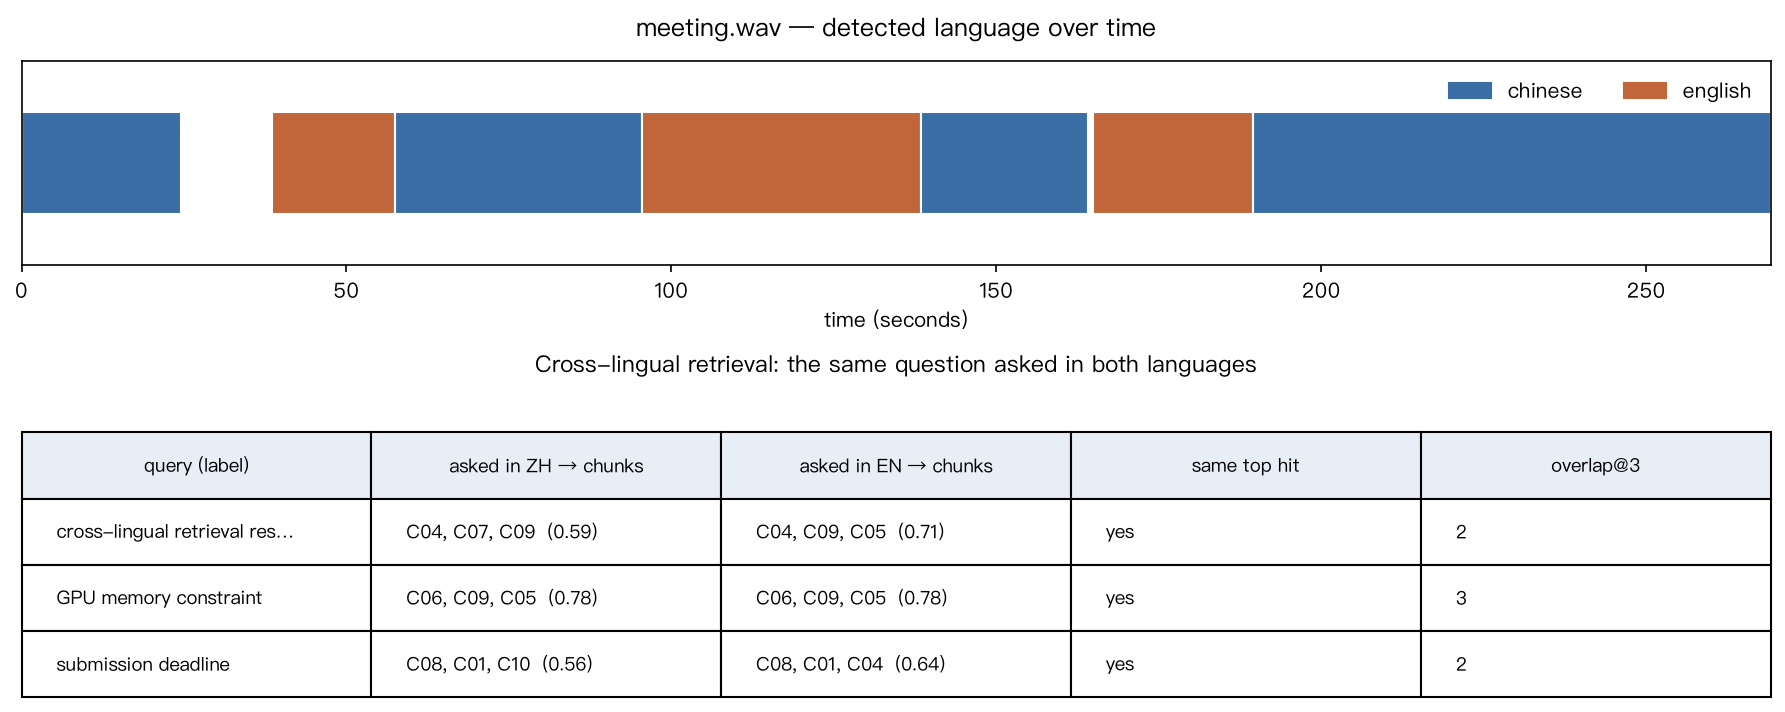

In [13]:
from IPython.display import Image, display

display(Image(filename=multilingual["figure_path"]))

## 6 · Reliability and tests

The four conditions the brief asks for: normal input, an invalid or
missing file, a RAG question with no supporting evidence, and a tool or
agent error. Plus the deterministic invariants — `start <= end`, text
present on every segment, unit-norm embeddings, unique ids.

The fast suite runs without loading any model:

```bash
python -m tests.test_smoke              # 16 checks, about a second
python -m tests.test_smoke --with-models  # adds the LLM-backed checks
```

In [14]:
from media_assistant.reliability import run_reliability_checks

unanswerable = next(q.question for q in DEFAULT_RAG_QUESTIONS if q.category == "unanswerable")
normal = next(q.question for q in DEFAULT_RAG_QUESTIONS if q.category == "factual")

reliability = run_reliability_checks(
    assistant,
    unanswerable_question=unanswerable,
    normal_question=normal,
    failing_agent_request=FAILING_AGENT_TASK,
)

for case in reliability["cases"]:
    print(f"{'PASS' if case['passed'] else 'FAIL'}  {case['name']:42s} {case['detail']}")
print(f"\n{reliability['passed']}/{reliability['total']} checks passed")

INFO | PASS transcript: timestamps ordered — 55 segments checked


INFO | PASS transcript: text present — 55 segments checked


INFO | PASS transcript: ids unique — 55 distinct ids


INFO | PASS transcript: monotonic — checked pairwise


INFO | PASS transcript: language labels match the script — 55 segments checked, 0 disagreements


...

INFO | PASS rag: unanswerable question refused — top score 0.301 vs threshold 0.42; reason below_similarity_threshold


INFO | Agent finished after 1 step(s)


INFO | PASS agent: impossible task handled — stopped_because=final_answer, tool_calls=0


INFO | PASS agent: step limit enforced — 1 steps taken, limit 3


PASS  transcript: timestamps ordered             55 segments checked
PASS  transcript: text present                   55 segments checked
PASS  transcript: ids unique                     55 distinct ids
PASS  transcript: monotonic                      checked pairwise
PASS  transcript: language labels match the script 55 segments checked, 0 disagreements
PASS  index: one embedding per chunk             11 vectors for 11 chunks
PASS  index: embeddings normalised               norm range 1.0000–1.0000
PASS  index: chunk ids unique                    11 chunks
PASS  index: chunks are single-language          languages: ['chinese', 'english']
PASS  media: missing file                        FileNotFoundError: Media file not found: definitely_not_a_real_file.wav
PASS  media: not a media file                    MediaError: Could not decode not_really_audio.wav: ffmpeg reported 'Invalid data found when processing input'. The file may be corrupt or may not be a media fi…
PASS  media: empty fil

## 7 · Artifacts

Writes `transcript.json`, `analysis.json`, `report.md`, the bilingual
transcript, and the visual output.

In [15]:
from media_assistant.report import write_artifacts

written = write_artifacts(
    assistant,
    output_dir=".",
    rag_results=rag_results,
    agent_run=agent_run,
    multilingual=multilingual,
    reliability=reliability,
)
for label, path in written.items():
    print(f"{label:22s} {path}")

assistant.release_all()   # give the models' memory back

INFO | Releasing LLM Qwen/Qwen3-4B-Instruct-2507


transcript             transcript.json
analysis               analysis.json
report                 report.md
visual                 visual_output.png
bilingual_transcript   transcript_bilingual.json


INFO | Releasing embedding model Qwen/Qwen3-Embedding-0.6B
